In [18]:
!pip -q install statsmodels openpyxl scikit-learn

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
file_path = "/content/RetailIQ_Final.xlsx"

sheets = pd.read_excel(
    file_path,
    sheet_name=None
)

df1 = sheets["Year 2009-2010"]
df2 = sheets["Year 2010-2011"]

df_combined = pd.concat(
    [df1, df2],
    ignore_index=True
)

df_combined = df_combined.drop_duplicates().reset_index(drop=True)

df_combined["InvoiceDate"] = pd.to_datetime(
    df_combined["InvoiceDate"]
)

df_combined["Revenue"] = pd.to_numeric(
    df_combined["Revenue"],
    errors="coerce"
).fillna(0)

print("Dataset Shape:", df_combined.shape)
print("Total Revenue:", df_combined["Revenue"].sum())

Dataset Shape: (1033036, 14)
Total Revenue: 20476260.448000003


In [4]:
monthly_sales = (
    df_combined
    .set_index("InvoiceDate")["Revenue"]
    .resample("MS")
    .sum()
)

monthly_sales = monthly_sales.asfreq("MS").fillna(0)

print(monthly_sales)

InvoiceDate
2009-12-01     822,483.95
2010-01-01     651,155.11
2010-02-01     551,504.73
2010-03-01     830,915.26
2010-04-01     678,875.25
2010-05-01     657,705.50
2010-06-01     749,537.31
2010-07-01     648,810.27
2010-08-01     695,251.91
2010-09-01     921,696.99
2010-10-01   1,161,902.22
2010-11-01   1,464,293.14
2010-12-01     821,452.73
2011-01-01     689,811.61
2011-02-01     522,545.56
2011-03-01     716,215.26
2011-04-01     536,968.49
2011-05-01     769,296.61
2011-06-01     760,547.01
2011-07-01     718,076.12
2011-08-01     757,841.38
2011-09-01   1,056,435.19
2011-10-01   1,151,263.73
2011-11-01   1,503,866.78
2011-12-01     637,808.33
Freq: MS, Name: Revenue, dtype: float64


In [5]:
last_month = monthly_sales.index.max()

monthly_sales = monthly_sales[
    monthly_sales.index < last_month
]

print("Monthly Observations:", len(monthly_sales))

print(
    "Forecasting Period:",
    monthly_sales.index.min(),
    "to",
    monthly_sales.index.max()
)

Monthly Observations: 24
Forecasting Period: 2009-12-01 00:00:00 to 2011-11-01 00:00:00


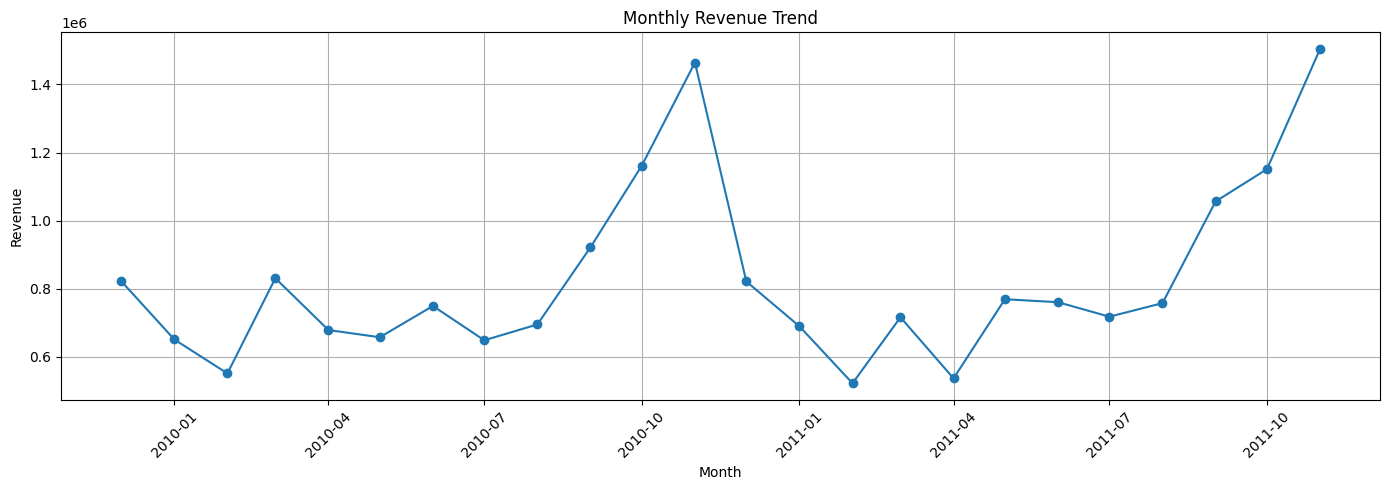

In [6]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

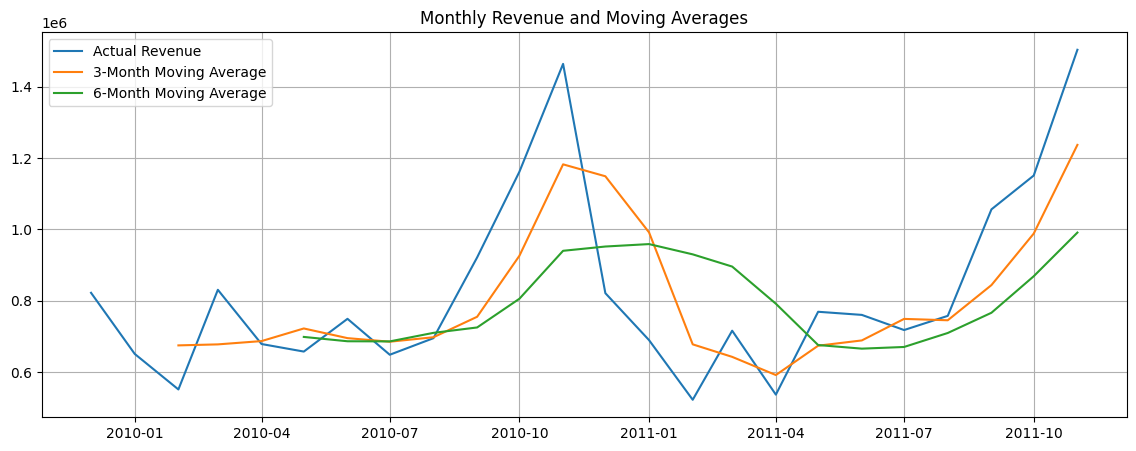

In [7]:
monthly_analysis = pd.DataFrame({
    "Revenue": monthly_sales
})

monthly_analysis["3_Month_Moving_Average"] = (
    monthly_analysis["Revenue"].rolling(3).mean()
)

monthly_analysis["6_Month_Moving_Average"] = (
    monthly_analysis["Revenue"].rolling(6).mean()
)

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_analysis["Revenue"],
    label="Actual Revenue"
)

plt.plot(
    monthly_analysis["3_Month_Moving_Average"],
    label="3-Month Moving Average"
)

plt.plot(
    monthly_analysis["6_Month_Moving_Average"],
    label="6-Month Moving Average"
)

plt.title("Monthly Revenue and Moving Averages")
plt.legend()
plt.grid(True)
plt.show()

In [8]:
test_size = 6

train = monthly_sales.iloc[:-test_size]
test = monthly_sales.iloc[-test_size:]

print("Training Observations:", len(train))
print("Testing Observations:", len(test))

print("\nTraining Period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting Period:")
print(test.index.min(), "to", test.index.max())

Training Observations: 18
Testing Observations: 6

Training Period:
2009-12-01 00:00:00 to 2011-05-01 00:00:00

Testing Period:
2011-06-01 00:00:00 to 2011-11-01 00:00:00


In [9]:
def naive_forecast(history):
    return history.iloc[-1]


def seasonal_naive_forecast(history):
    return history.iloc[-12]


def arima_forecast(history):

    model = ARIMA(
        history,
        order=(1, 1, 1)
    )

    fitted_model = model.fit()

    return fitted_model.forecast(steps=1).iloc[0]


def sarima_forecast(history):

    model = SARIMAX(
        history,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 0, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted_model = model.fit(
        disp=False,
        maxiter=200
    )

    return fitted_model.forecast(steps=1).iloc[0]

In [10]:
forecasting_models = {

    "Naive": naive_forecast,

    "Seasonal Naive": seasonal_naive_forecast,

    "ARIMA": arima_forecast,

    "SARIMA": sarima_forecast

}

rolling_predictions = {}

for model_name, forecast_function in forecasting_models.items():

    predictions = []

    history = train.copy()

    print(f"\nRunning {model_name}...")

    for current_date in test.index:

        try:

            prediction = forecast_function(history)

            predictions.append(float(prediction))

        except Exception as e:

            print(
                f"{model_name} failed for {current_date}: {e}"
            )

            predictions.append(np.nan)

        # Expand training window
        history = pd.concat([
            history,
            test.loc[[current_date]]
        ])

    rolling_predictions[model_name] = predictions


Running Naive...

Running Seasonal Naive...

Running ARIMA...

Running SARIMA...


In [11]:
def calculate_smape(actual, predicted):

    actual = np.array(actual)
    predicted = np.array(predicted)

    denominator = (
        np.abs(actual) + np.abs(predicted)
    )

    denominator = np.where(
        denominator == 0,
        1,
        denominator
    )

    return np.mean(
        2 * np.abs(actual - predicted) /
        denominator
    ) * 100


results = []

for model_name, predictions in rolling_predictions.items():

    predictions = np.array(predictions)

    if not np.isfinite(predictions).all():
        print(f"Skipping incomplete results for {model_name}")
        continue

    actual = test.values

    mae = mean_absolute_error(
        actual,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(actual, predictions)
    )

    smape = calculate_smape(
        actual,
        predictions
    )

    r2 = r2_score(
        actual,
        predictions
    )

    results.append({

        "Model": model_name,

        "MAE": mae,

        "RMSE": rmse,

        "sMAPE (%)": smape,

        "R2": r2

    })


evaluation_results = pd.DataFrame(results)

evaluation_results = evaluation_results.sort_values(
    by="RMSE"
).reset_index(drop=True)

evaluation_results

,Model,MAE,RMSE,sMAPE (%),R2
0,Seasonal Naive,"54,635.89","69,125.55",6.24,0.94
1,SARIMA,"109,790.45","123,993.22",11.85,0.81
2,Naive,"139,501.86","194,053.79",13.39,0.52
3,ARIMA,"164,300.97","228,407.28",15.60,0.34


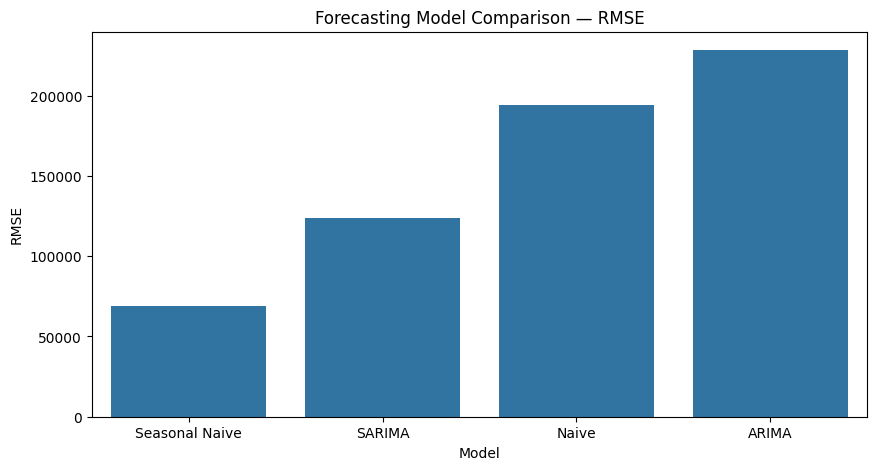

In [12]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=evaluation_results,
    x="Model",
    y="RMSE"
)

plt.title("Forecasting Model Comparison — RMSE")
plt.ylabel("RMSE")
plt.xlabel("Model")

plt.show()

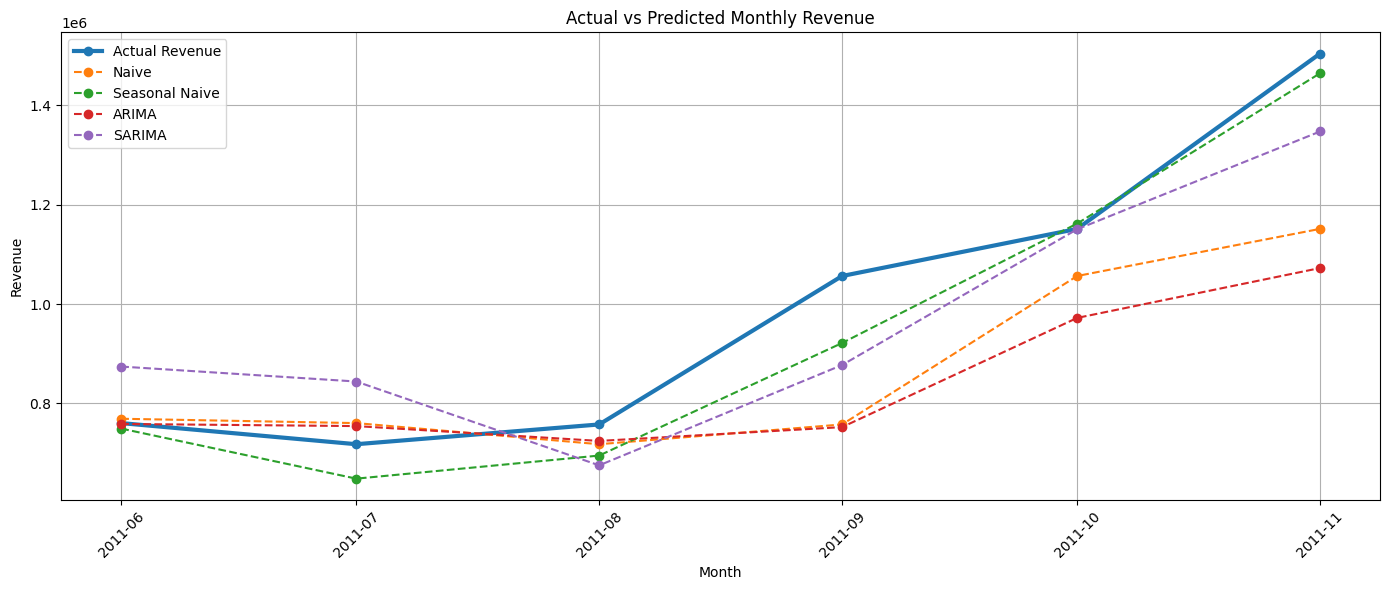

In [13]:
plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test.values,
    marker="o",
    linewidth=3,
    label="Actual Revenue"
)

for model_name, predictions in rolling_predictions.items():

    if np.isfinite(predictions).all():

        plt.plot(
            test.index,
            predictions,
            marker="o",
            linestyle="--",
            label=model_name
        )

plt.title("Actual vs Predicted Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
best_model_name = evaluation_results.iloc[0]["Model"]

print("Best Model:", best_model_name)

print(
    "Best RMSE:",
    evaluation_results.iloc[0]["RMSE"]
)

print(
    "Best MAE:",
    evaluation_results.iloc[0]["MAE"]
)

print(
    "Best sMAPE:",
    evaluation_results.iloc[0]["sMAPE (%)"]
)

Best Model: Seasonal Naive
Best RMSE: 69125.54576816091
Best MAE: 54635.89166666666
Best sMAPE: 6.236130119840844


In [15]:
forecast_horizon = 3

if best_model_name == "Naive":

    future_predictions = [
        float(monthly_sales.iloc[-1])
    ] * forecast_horizon


elif best_model_name == "Seasonal Naive":

    future_predictions = [
        float(monthly_sales.iloc[-12 + i])
        for i in range(forecast_horizon)
    ]


elif best_model_name == "ARIMA":

    final_model = ARIMA(
        monthly_sales,
        order=(1, 1, 1)
    )

    final_fit = final_model.fit()

    future_predictions = final_fit.forecast(
        steps=forecast_horizon
    ).values


elif best_model_name == "SARIMA":

    final_model = SARIMAX(
        monthly_sales,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 0, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    final_fit = final_model.fit(
        disp=False,
        maxiter=200
    )

    future_predictions = final_fit.forecast(
        steps=forecast_horizon
    ).values


future_dates = pd.date_range(
    start=monthly_sales.index[-1] + pd.DateOffset(months=1),
    periods=forecast_horizon,
    freq="MS"
)

future_forecast = pd.DataFrame({

    "Month": future_dates,

    "Predicted_Revenue": future_predictions

})

future_forecast

,Month,Predicted_Revenue
0,2011-12-01,"821,452.73"
1,2012-01-01,"689,811.61"
2,2012-02-01,"522,545.56"


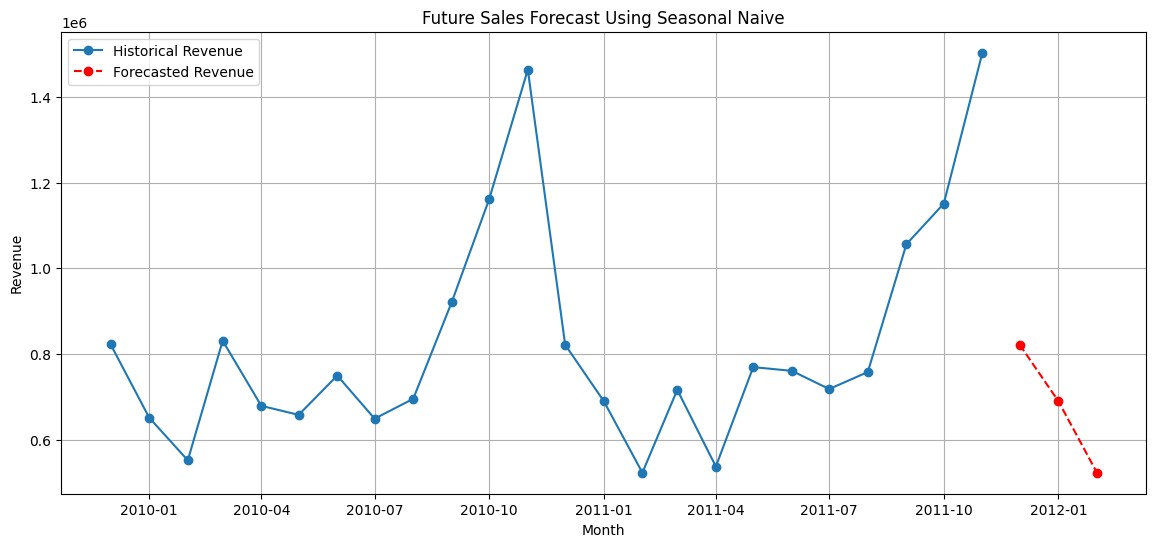

In [16]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    label="Historical Revenue"
)

plt.plot(
    future_forecast["Month"],
    future_forecast["Predicted_Revenue"],
    marker="o",
    linestyle="--",
    color="red",
    label="Forecasted Revenue"
)

plt.title(
    f"Future Sales Forecast Using {best_model_name}"
)

plt.xlabel("Month")
plt.ylabel("Revenue")

plt.legend()
plt.grid(True)
plt.show()

In [17]:
evaluation_results.to_csv(
    "forecasting_model_evaluation.csv",
    index=False
)

future_forecast.to_csv(
    "future_sales_forecast.csv",
    index=False
)

forecast_comparison = pd.DataFrame(
    rolling_predictions,
    index=test.index
)

forecast_comparison["Actual_Revenue"] = test

forecast_comparison.to_csv(
    "rolling_forecast_predictions.csv"
)

print("Sales forecasting completed.")

Sales forecasting completed.
